# COMM061 : NLP
# Coursework: BESSTIE Sequence Classification 
# Group 29
# **Task:** Sentiment and Sarcasm detection across three English varieties (en-AU, en-IN, en-UK)  
# **Dataset:** surrey-nlp/BESSTIE-CW-26 (6,243 samples)

In [6]:
import sys
import os
import warnings

# Add the current directory to the path to allow importing from src
sys.path.insert(0, os.path.abspath('.'))

# Filter out warnings
warnings.filterwarnings('ignore')

# Import constants from your config file
from src.config import SEEDS, VARIETIES, TASKS, RESULTS_DIR, FIGURES_DIR

# Print configuration details
print(f"Seeds: {SEEDS}")
print(f"Varieties: {VARIETIES}")
print(f"Tasks: {TASKS}")

Seeds: [42, 123]
Varieties: ['en-AU', 'en-IN', 'en-UK']
Tasks: ['Sentiment', 'Sarcasm']


---## ***Q1: Data Analysis and Visualisation· Max 4 pages in report***

### Q1.1 — Label DistributionsVisualise Sentiment and Sarcasm class distributions across all three varieties.  Comment on the sarcasm class imbalance (en-IN ~7%, en-UK ~8% vs en-AU ~29%).

     split variety  total  positive_sentiment  negative_sentiment  sarcastic  not_sarcastic  google  reddit
     train   en-AU   1145                 512                 633        337            808     389     756
     train   en-IN   1399                 710                 689         95           1304     716     683
     train   en-UK   1203                 618                 585         92           1111     769     434
validation   en-AU     95                  45                  50         28             67      39      56
validation   en-IN    117                  53                  64          8            109      62      55
validation   en-UK    101                  55                  46          8             93      66      35
      test   en-AU    667                 320                 347        196            471     244     423
      test   en-IN    816                 386                 430         56            760     405     411
      test   en-UK    700   

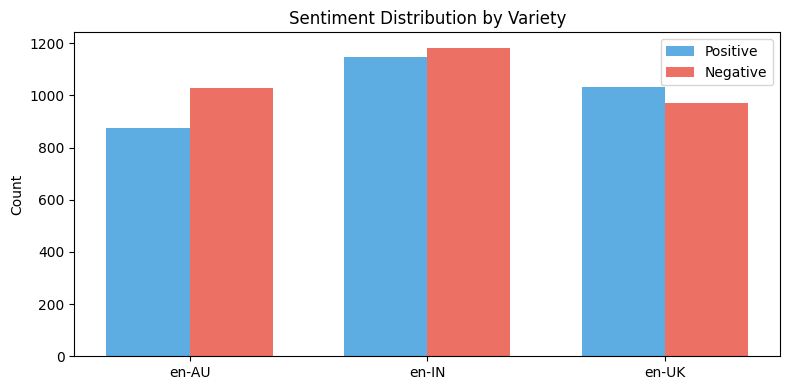

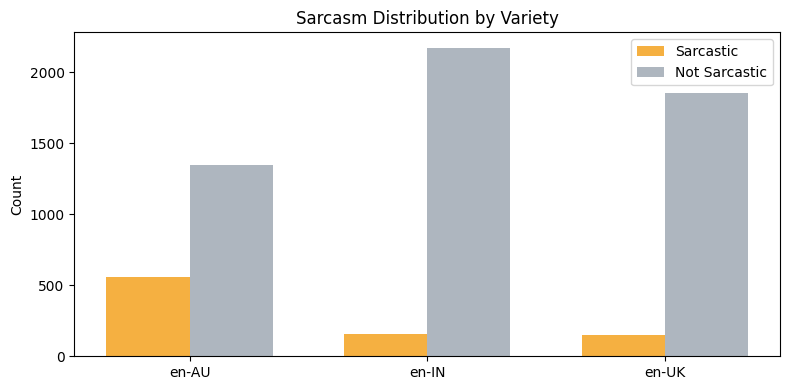

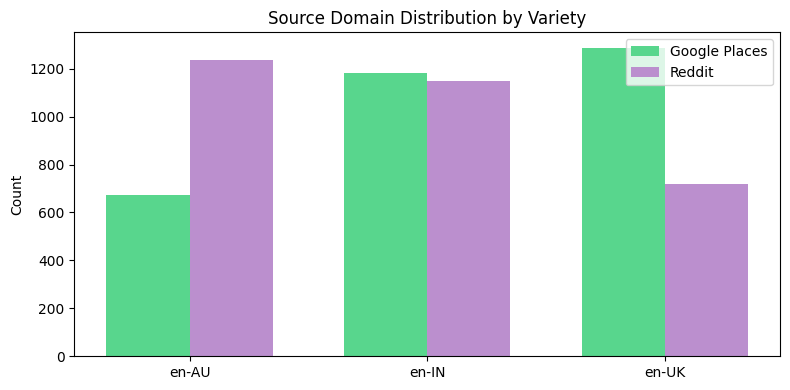

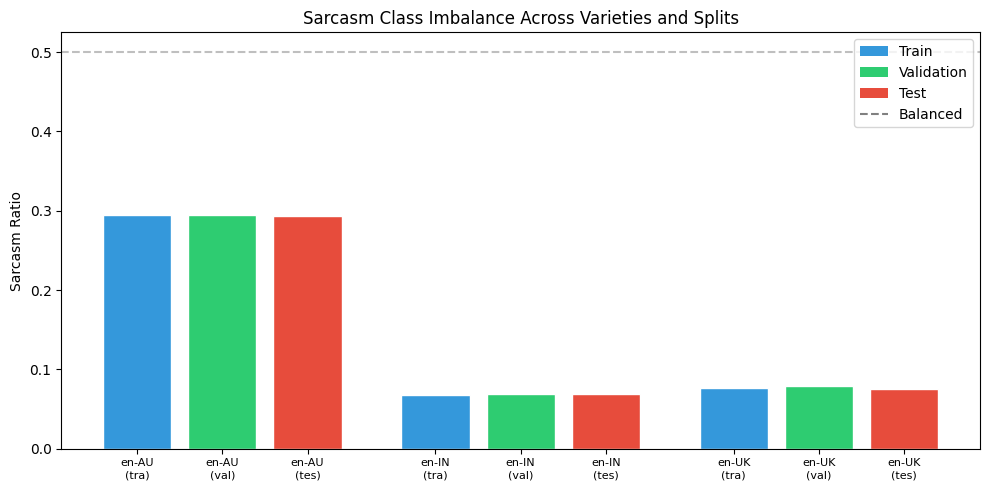

In [2]:
from src.data.loader import get_split_stats
from src.data.analysis import plot_label_distributions, plot_sarcasm_imbalance_per_split

# Get and print split statistics
stats = get_split_stats()
print(stats.to_string(index=False))

# Generate and save distribution plots
label_stats = plot_label_distributions(save=True)
plot_sarcasm_imbalance_per_split(save=True)

### Q1.2 — Vocabulary OverlapCalculate overlap between en-UK (inner-circle) and en-IN (outer-circle) using:- Jaccard similarity on unique token sets- Cosine similarity on mean TF-IDF vectors

In [3]:
from src.data.analysis import compute_vocab_overlap

# Compute the vocabulary overlap between the two language varieties
overlap = compute_vocab_overlap(variety_a="en-UK", variety_b="en-IN")
print(overlap)


Vocabulary Overlap: en-UK vs en-IN
  en-UK vocab size: 7,472
  en-IN vocab size: 7,337
  Overlap:             3,353
  Jaccard similarity:  0.2927
  TF-IDF cosine:       0.8812
{'variety_a': 'en-UK', 'variety_b': 'en-IN', 'vocab_size_a': 7472, 'vocab_size_b': 7337, 'overlap_size': 3353, 'jaccard_similarity': 0.2927, 'tfidf_cosine_similarity': 0.8812}


C:\Users\shah\Desktop\university\semester 2\NLP\.nlp_venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


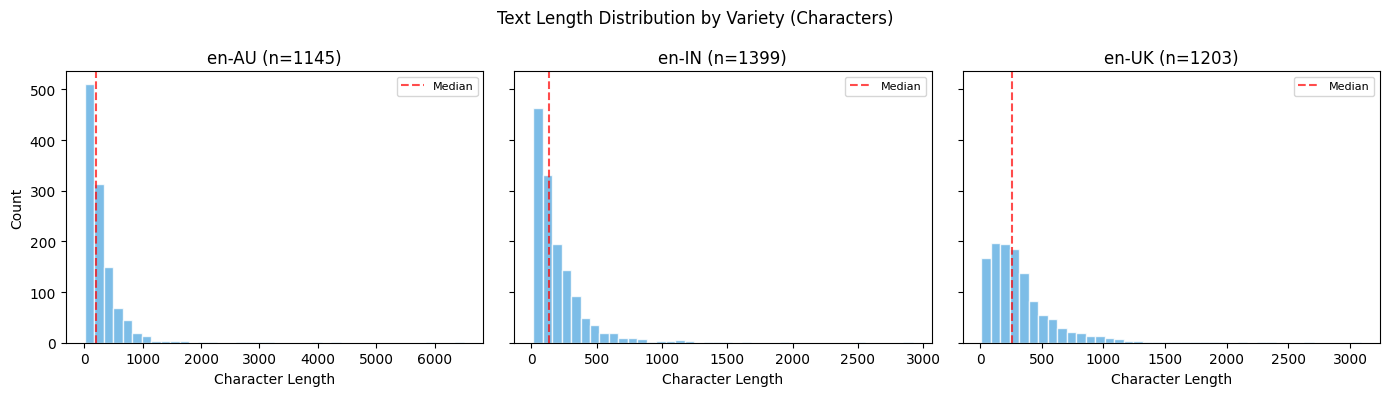

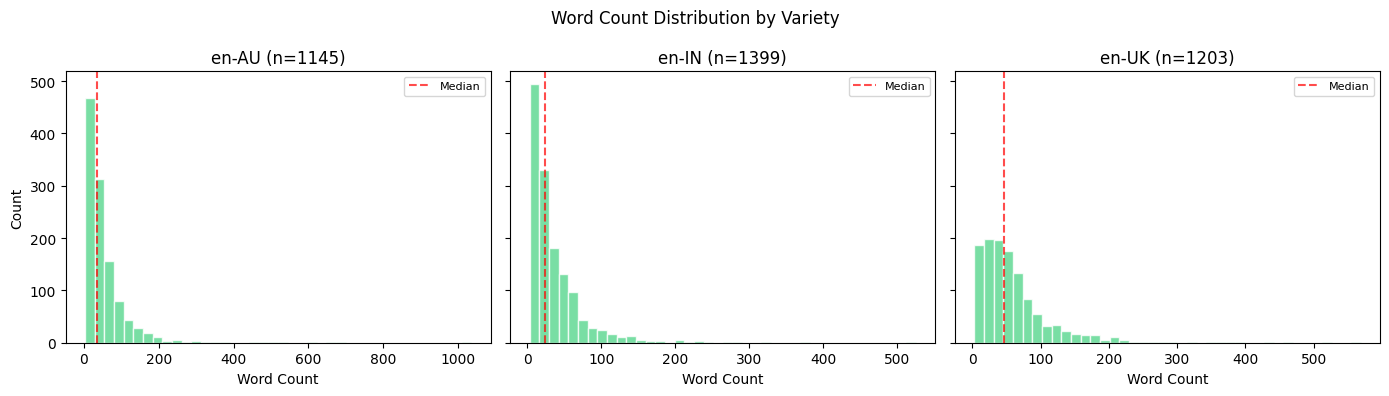


  Text Length Summary (training set):
         mean_chars  median_chars  mean_words  median_words
variety                                                    
en-AU         307.5         199.0        55.2          36.0
en-IN         202.1         132.0        36.2          24.0
en-UK         332.9         257.0        60.9          47.0


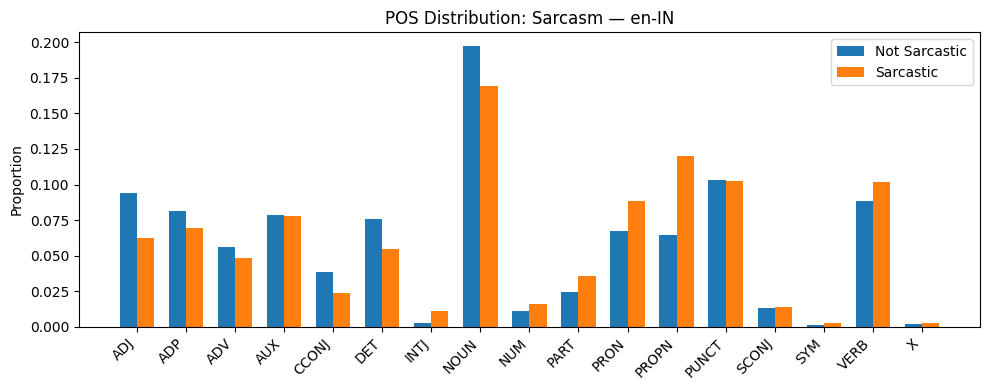

In [1]:
from src.data.analysis import plot_text_length_distribution, pos_distribution_by_label

# This generates q1_text_length_dist.png and q1_word_count_dist.png
plot_text_length_distribution()

# This generates q1_pos_sarcasm_en-IN.png (issue 3 as well)
pos_distribution_by_label("Sarcasm", "en-IN")

### POS Tag AnalysisCompare POS tag distributions between sarcastic and non-sarcastic samples.

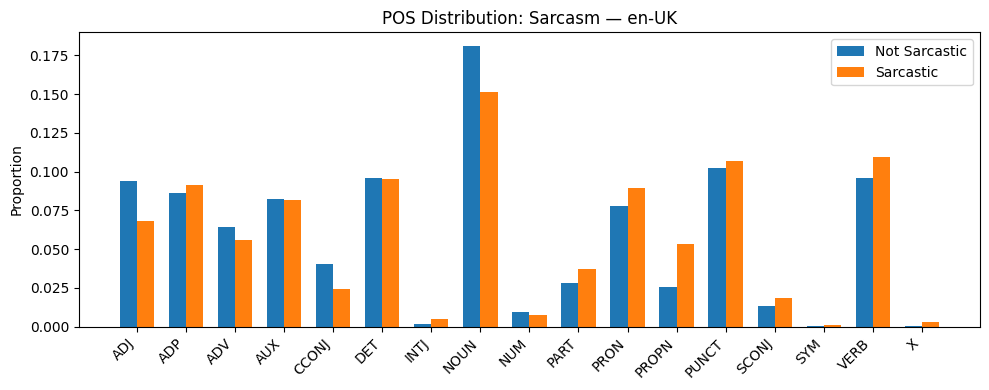

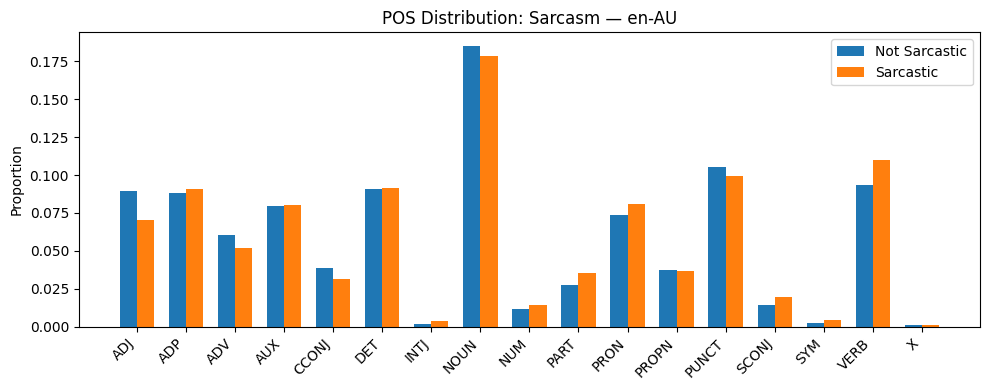

In [4]:
from src.data.analysis import pos_distribution_by_label

# Analyze POS distribution for UK variety
pos_distribution_by_label(task="Sarcasm", variety="en-UK", save=True)

# Analyze POS distribution for AU variety
pos_distribution_by_label(task="Sarcasm", variety="en-AU", save=True)

---## Q2: Experimentation (40 marks)*Max 6 pages in report for Q2.1 + Q2.2 + Q2.3 combined*

### Q2.1 — Baseline vs Transformer. Compare classical baselines (TF-IDF + LogReg, TF-IDF + SVM) against fine-tuned RoBERTa-base.  Both tasks, 2 seeds each. Focus the report on *why* pre-training helps (or doesn't).

#### Classical Baselines

In [1]:
from src.models.classical import run_classical_baselines

# Run the classical baseline models and store the results in a DataFrame
df_classical = run_classical_baselines()

# Display the DataFrame
df_classical

C:\Users\shah\Desktop\university\semester 2\NLP\.nlp_venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  Training logreg on Sentiment (seed=42)...


  Training svm on Sentiment (seed=42)...
  Training logreg on Sarcasm (seed=42)...
  Training svm on Sarcasm (seed=42)...
  Training logreg on Sentiment (seed=123)...
  Training svm on Sentiment (seed=123)...
  Training logreg on Sarcasm (seed=123)...
  Training svm on Sarcasm (seed=123)...

Saved to C:\Users\shah\Desktop\university\semester 2\NLP\coursework\COMM061_Project\results\q21_classical_baselines.csv


,experiment,model,task,variety,seed,macro_f1,precision_macro,recall_macro,f1_class_0,f1_class_1,precision_class_0,precision_class_1,recall_class_0,recall_class_1,majority_class_only
0,Q2.1,logreg,Sentiment,all,42,0.8287,0.8300,0.8285,0.8369,0.8206,0.8179,0.8421,0.8568,0.8002,False
1,Q2.1,logreg,Sentiment,en-AU,42,0.7994,0.8181,0.7991,0.8283,0.7706,0.7596,0.8765,0.9107,0.6875,False
2,Q2.1,logreg,Sentiment,en-IN,42,0.7983,0.7986,0.7980,0.8106,0.7859,0.8050,0.7921,0.8163,0.7798,False
3,Q2.1,logreg,Sentiment,en-UK,42,0.8882,0.8905,0.8876,0.8815,0.8949,0.9119,0.8691,0.8529,0.9222,False
4,Q2.1,svm,Sentiment,all,42,0.8407,0.8418,0.8404,0.8480,0.8334,0.8302,0.8535,0.8666,0.8143,False
5,Q2.1,svm,Sentiment,en-AU,42,0.8298,0.8406,0.8288,0.8495,0.8102,0.7960,0.8852,0.9107,0.7469,False
6,Q2.1,svm,Sentiment,en-IN,42,0.8043,0.8049,0.8040,0.8170,0.7916,0.8087,0.8011,0.8256,0.7824,False
7,Q2.1,svm,Sentiment,en-UK,42,0.8912,0.8919,0.8909,0.8866,0.8959,0.9000,0.8838,0.8735,0.9083,False
8,Q2.1,logreg,Sarcasm,all,42,0.6275,0.6143,0.6688,0.8620,0.3931,0.9130,0.3155,0.8163,0.5213,False
9,Q2.1,logreg,Sarcasm,en-AU,42,0.6715,0.6697,0.6736,0.8030,0.5400,0.8099,0.5294,0.7962,0.5510,False


#### Fine-tuned RoBERTa

In [3]:
from src.models.transformer import run_transformer_experiment

# Run the RoBERTa (or similar transformer) experiment
df_roberta = run_transformer_experiment()

# Display the resulting DataFrame
df_roberta


  Fine-tuning RoBERTa on Sentiment (seed=42)...


Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████████████████| 197/197 [00:00<00:00, 2940.61it/s]
RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.bias        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consi

Epoch,Training Loss,Validation Loss,Macro F1
1,0.321927,0.181286,0.932809
2,0.240317,0.188328,0.923322
3,0.231957,0.232946,0.936096
4,0.143664,0.216927,0.945631


Writing model shards: 100%|████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.98it/s]
C:\Users\shah\Desktop\university\semester 2\NLP\.nlp_venv\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  2.38it/s]
C:\Users\shah\Desktop\university\semester 2\NLP\.nlp_venv\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  2.38it/s]
C:\Users\shah\Desktop\university


  Fine-tuning RoBERTa on Sarcasm (seed=42)...


Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████████████████| 197/197 [00:00<00:00, 4264.13it/s]
RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.bias        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consi

... (7 outputs left out)

Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████████████████| 197/197 [00:00<00:00, 4286.92it/s]
RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.bias        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consi

Epoch,Training Loss,Validation Loss,Macro F1
1,0.581182,0.663022,0.629069
2,0.474321,0.588864,0.669441
3,0.350566,0.723543,0.639039
4,0.236592,0.966404,0.663157


Writing model shards: 100%|████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  2.45it/s]
C:\Users\shah\Desktop\university\semester 2\NLP\.nlp_venv\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  2.15it/s]
C:\Users\shah\Desktop\university\semester 2\NLP\.nlp_venv\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  2.36it/s]
C:\Users\shah\Desktop\university

,experiment,model,task,variety,seed,macro_f1,precision_macro,recall_macro,f1_class_0,f1_class_1,precision_class_0,precision_class_1,recall_class_0,recall_class_1,majority_class_only
0,Q2.1,roberta-base,Sentiment,all,42,0.8983,0.8983,0.8985,0.8995,0.8971,0.9102,0.8864,0.8890,0.9081,False
1,Q2.1,roberta-base,Sentiment,en-AU,42,0.8978,0.8984,0.8974,0.9031,0.8924,0.8930,0.9038,0.9135,0.8812,False
2,Q2.1,roberta-base,Sentiment,en-IN,42,0.8541,0.8542,0.8553,0.8578,0.8503,0.8821,0.8264,0.8349,0.8756,False
3,Q2.1,roberta-base,Sentiment,en-UK,42,0.9499,0.9508,0.9495,0.9477,0.9521,0.9635,0.9380,0.9324,0.9667,False
4,Q2.1,roberta-base,Sarcasm,all,42,0.7201,0.6970,0.7615,0.9051,0.5351,0.9388,0.4552,0.8738,0.6492,False
5,Q2.1,roberta-base,Sarcasm,en-AU,42,0.7782,0.7777,0.7786,0.8693,0.6870,0.8702,0.6853,0.8684,0.6888,False
6,Q2.1,roberta-base,Sarcasm,en-IN,42,0.5820,0.5690,0.6220,0.9170,0.2469,0.9493,0.1887,0.8868,0.3571,False
7,Q2.1,roberta-base,Sarcasm,en-UK,42,0.6917,0.6541,0.8369,0.9185,0.4649,0.9824,0.3258,0.8624,0.8113,False
8,Q2.1,roberta-base,Sentiment,all,123,0.8937,0.8951,0.8945,0.8925,0.8949,0.9251,0.8651,0.8621,0.9268,False
9,Q2.1,roberta-base,Sentiment,en-AU,123,0.9055,0.9053,0.9058,0.9083,0.9026,0.9176,0.8930,0.8991,0.9125,False


#### Q2.1 — Comparison

In [6]:
import pandas as pd

# Combine classical + transformer results
q21_classical = pd.read_csv(RESULTS_DIR / "q21_classical_baselines.csv")
q21_roberta = pd.read_csv(RESULTS_DIR / "q21_roberta.csv")
q21_all = pd.concat([q21_classical, q21_roberta], ignore_index=True)

# Average across seeds for the summary table
summary = q21_all.groupby(["model", "task", "variety"])[
    ["macro_f1", "precision_macro", "recall_macro"]
].mean().round(4)

print(summary.to_string())

                                macro_f1  precision_macro  recall_macro
model        task      variety                                         
logreg       Sarcasm   all        0.6275           0.6143        0.6688
                       en-AU      0.6715           0.6697        0.6736
                       en-IN      0.5471           0.5491        0.6272
                       en-UK      0.5895           0.5771        0.6657
             Sentiment all        0.8287           0.8300        0.8285
                       en-AU      0.7994           0.8181        0.7991
                       en-IN      0.7983           0.7986        0.7980
                       en-UK      0.8882           0.8905        0.8876
roberta-base Sarcasm   all        0.7037           0.6878        0.7296
                       en-AU      0.7452           0.7527        0.7406
                       en-IN      0.5710           0.5611        0.5974
                       en-UK      0.6908           0.6544       

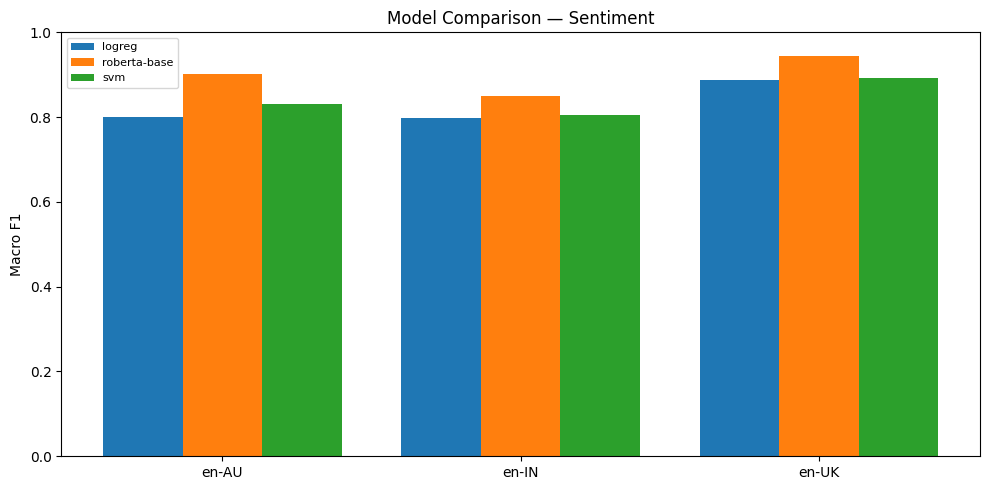

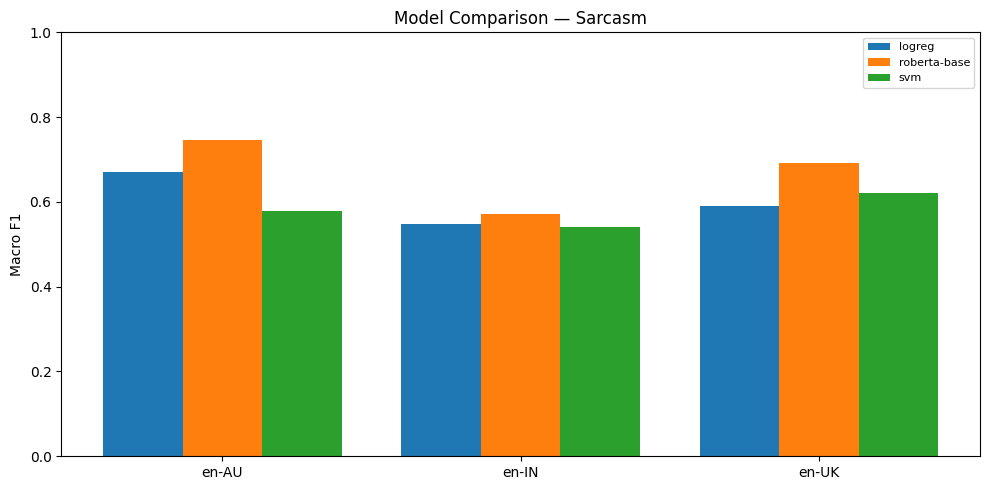

In [7]:
from src.evaluation.visualisation import plot_model_comparison

# Generate and save comparison plot for Sentiment task
plot_model_comparison(q21_all, task="Sentiment", save_name="q21_comparison_sentiment.png")

# Generate and save comparison plot for Sarcasm task
plot_model_comparison(q21_all, task="Sarcasm", save_name="q21_comparison_sarcasm.png")

### Q2.2 — Cross-Variety Evaluation *M2* Train RoBERTa per variety for Sentiment. Test each on all three test sets.  Analyse: does AU→UK transfer better than AU→IN?

In [1]:
from src.models.transformer import run_cross_variety_experiment

# Run the cross-variety experiment for the Sentiment task
# This returns both the performance matrix and a detailed DataFrame
matrix, df_cross = run_cross_variety_experiment(task="Sentiment")

# Display the averaged Macro-F1 performance matrix
print("\nCross-variety matrix (Macro-F1, averaged across seeds):")
print(matrix.round(4))

C:\Users\shah\Desktop\university\semester 2\NLP\.nlp_venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



  Training on en-AU for Sentiment (seed=42)...


Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████████████████| 197/197 [00:00<00:00, 3791.33it/s]
RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
classifier.out_proj.bias        | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.dense.weight         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consi

Epoch,Training Loss,Validation Loss,Macro F1
1,0.627579,0.269167,0.873670
2,0.330578,0.153052,0.936497
3,0.168832,0.250727,0.946779
4,0.104211,0.240786,0.946993


Writing model shards: 100%|████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  2.23it/s]
C:\Users\shah\Desktop\university\semester 2\NLP\.nlp_venv\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  2.25it/s]
C:\Users\shah\Desktop\university\semester 2\NLP\.nlp_venv\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  2.37it/s]
C:\Users\shah\Desktop\university


  Training on en-IN for Sentiment (seed=42)...


... (16 outputs left out)

Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████████████████| 197/197 [00:00<00:00, 3757.58it/s]
RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
classifier.out_proj.bias        | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.dense.weight         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consi

Epoch,Training Loss,Validation Loss,Macro F1
1,0.600651,0.284032,0.888956
2,0.143209,0.152725,0.950320
3,0.116455,0.283015,0.940119
4,0.046664,0.169719,0.960299


Writing model shards: 100%|████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.56it/s]
C:\Users\shah\Desktop\university\semester 2\NLP\.nlp_venv\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.17it/s]
C:\Users\shah\Desktop\university\semester 2\NLP\.nlp_venv\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.35it/s]
C:\Users\shah\Desktop\university


Cross-variety matrix (Macro-F1):
        en-AU   en-IN   en-UK
en-AU  0.8970  0.8063  0.9414
en-IN  0.8822  0.8404  0.9406
en-UK  0.8780  0.8360  0.9484

Cross-variety matrix (Macro-F1, averaged across seeds):
        en-AU   en-IN   en-UK
en-AU  0.8970  0.8063  0.9414
en-IN  0.8822  0.8404  0.9406
en-UK  0.8780  0.8360  0.9484


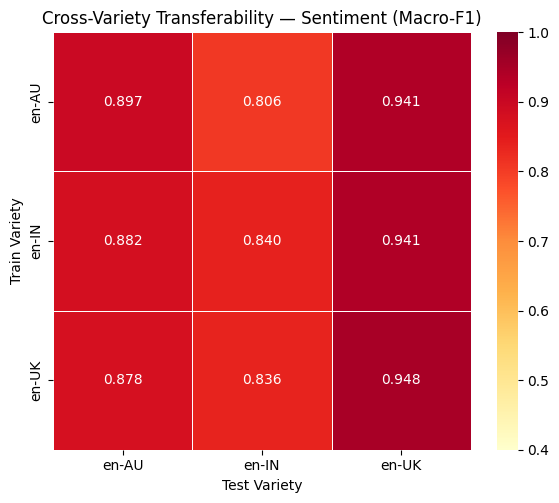

In [2]:
from src.evaluation.visualisation import plot_cross_variety_heatmap

# Generate and save the heatmap for the Cross-variety Sentiment analysis
plot_cross_variety_heatmap(matrix, task="Sentiment", save_name="q22_heatmap.png")

### Q2.3 — LoRA adapters on Qwen2.5-1.5B-Instruct per variety for Sarcasm detection.  Compare UK/AU/IN adapters on all test sets.

In [1]:
from src.models.lora_adapter import run_lora_experiment

# Set max_samples=500 to reduce GPU time if needed (spec allows this)
# Running with max_samples=None uses the full dataset
df_lora, adapter_paths = run_lora_experiment(max_samples=None)

# Display the results DataFrame
df_lora

C:\Users\shah\Desktop\university\semester 2\venv311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



  Training LoRA on en-AU for Sarcasm (seed=42)...


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|█████████████████████████████████████████████████████████████| 338/338 [00:01<00:00, 270.27it/s]
[transformers] Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-1.5B-Instruct
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 1,092,608 || all params: 1,544,809,984 || trainable%: 0.0707


[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.
[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!


Epoch,Training Loss,Validation Loss,Macro F1
1,1.423195,0.724043,0.680135
2,0.848599,0.673662,0.647143
3,0.597898,0.638715,0.643550


... (59 outputs left out)

    Evaluating on en-UK...


Loading weights: 100%|█████████████████████████████████████████████████████████████| 338/338 [00:00<00:00, 378.97it/s]
[transformers] Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-1.5B-Instruct
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Saved to C:\Users\shah\Desktop\university\semester 2\nLP\coursework\cOMM061_Project\results\q23_lora.csv


,experiment,model,task,variety,seed,macro_f1,precision_macro,recall_macro,f1_class_0,f1_class_1,precision_class_0,precision_class_1,recall_class_0,recall_class_1,majority_class_only,train_variety
0,Q2.3,lora-en-AU,Sarcasm,en-AU,42,0.7031,0.6979,0.7108,0.8148,0.5913,0.8367,0.5591,0.7941,0.6276,False,en-AU
1,Q2.3,lora-en-AU,Sarcasm,en-IN,42,0.5203,0.5523,0.6797,0.8107,0.2298,0.9655,0.1391,0.6987,0.6607,False,en-AU
2,Q2.3,lora-en-AU,Sarcasm,en-UK,42,0.5914,0.5948,0.7805,0.8494,0.3333,0.9798,0.2098,0.7496,0.8113,False,en-AU
3,Q2.3,lora-en-IN,Sarcasm,en-AU,42,0.4475,0.6474,0.5125,0.8277,0.0673,0.7115,0.5833,0.9894,0.0357,False,en-IN
4,Q2.3,lora-en-IN,Sarcasm,en-IN,42,0.5677,0.6213,0.5520,0.9581,0.1772,0.9382,0.3043,0.9789,0.1250,False,en-IN
5,Q2.3,lora-en-IN,Sarcasm,en-UK,42,0.5124,0.6061,0.5150,0.9582,0.0667,0.9264,0.2857,0.9923,0.0377,False,en-IN
6,Q2.3,lora-en-UK,Sarcasm,en-AU,42,0.4957,0.6396,0.5325,0.8261,0.1652,0.7204,0.5588,0.9682,0.0969,False,en-UK
7,Q2.3,lora-en-UK,Sarcasm,en-IN,42,0.5974,0.5974,0.5974,0.9447,0.2500,0.9447,0.2500,0.9447,0.2500,False,en-UK
8,Q2.3,lora-en-UK,Sarcasm,en-UK,42,0.6396,0.7024,0.6110,0.9583,0.3210,0.9405,0.4643,0.9768,0.2453,False,en-UK
9,Q2.3,lora-en-AU,Sarcasm,en-AU,123,0.7310,0.7237,0.7435,0.8282,0.6338,0.8604,0.5870,0.7983,0.6888,False,en-AU


In [7]:
import pandas as pd

# Build the LoRA cross-variety matrix
lora_results = pd.read_csv(RESULTS_DIR / "q23_lora.csv")

# Group and unstack to create the matrix format
lora_matrix = lora_results.groupby(["train_variety", "variety"])["macro_f1"].mean().unstack()

print("LoRA adapter cross-variety matrix (Macro-F1):")
print(lora_matrix.round(4))

LoRA adapter cross-variety matrix (Macro-F1):
variety         en-AU   en-IN   en-UK
train_variety                        
en-AU          0.7170  0.5120  0.5944
en-IN          0.4332  0.5651  0.5149
en-UK          0.4835  0.5976  0.6158


## Q3: Evaluation

In [1]:
from src.evaluation.visualisation import compile_all_results

# Compile all results from classical, transformer, and LoRA experiments
all_results = compile_all_results()

# Print summary statistics for the compiled data
print(f"Total experiment rows: {len(all_results)}")
print(f"Experiments: {all_results['experiment'].unique()}")
print(f"Models: {all_results['model'].unique()}")

# Display the first 20 rows of the consolidated DataFrame
all_results.head(20)

Total experiment rows: 87
Experiments: <ArrowStringArray>
['Q2.1', 'Q2.2', nan, 'Q2.3']
Length: 4, dtype: str
Models: <ArrowStringArray>
[       'logreg',           'svm',  'roberta-base', 'roberta-en-AU',
 'roberta-en-IN', 'roberta-en-UK',             nan,    'lora-en-AU',
    'lora-en-IN',    'lora-en-UK']
Length: 10, dtype: str


,experiment,model,task,variety,seed,macro_f1,precision_macro,recall_macro,f1_class_0,f1_class_1,precision_class_0,precision_class_1,recall_class_0,recall_class_1,majority_class_only,train_variety,Unnamed: 0,en-AU,en-IN,en-UK
0,Q2.1,logreg,Sentiment,all,42.0,0.8287,0.8300,0.8285,0.8369,0.8206,0.8179,0.8421,0.8568,0.8002,False,NaN,NaN,NaN,NaN,NaN
1,Q2.1,logreg,Sentiment,en-AU,42.0,0.7994,0.8181,0.7991,0.8283,0.7706,0.7596,0.8765,0.9107,0.6875,False,NaN,NaN,NaN,NaN,NaN
2,Q2.1,logreg,Sentiment,en-IN,42.0,0.7983,0.7986,0.7980,0.8106,0.7859,0.8050,0.7921,0.8163,0.7798,False,NaN,NaN,NaN,NaN,NaN
3,Q2.1,logreg,Sentiment,en-UK,42.0,0.8882,0.8905,0.8876,0.8815,0.8949,0.9119,0.8691,0.8529,0.9222,False,NaN,NaN,NaN,NaN,NaN
4,Q2.1,svm,Sentiment,all,42.0,0.8407,0.8418,0.8404,0.8480,0.8334,0.8302,0.8535,0.8666,0.8143,False,NaN,NaN,NaN,NaN,NaN
5,Q2.1,svm,Sentiment,en-AU,42.0,0.8298,0.8406,0.8288,0.8495,0.8102,0.7960,0.8852,0.9107,0.7469,False,NaN,NaN,NaN,NaN,NaN
6,Q2.1,svm,Sentiment,en-IN,42.0,0.8043,0.8049,0.8040,0.8170,0.7916,0.8087,0.8011,0.8256,0.7824,False,NaN,NaN,NaN,NaN,NaN
7,Q2.1,svm,Sentiment,en-UK,42.0,0.8912,0.8919,0.8909,0.8866,0.8959,0.9000,0.8838,0.8735,0.9083,False,NaN,NaN,NaN,NaN,NaN
8,Q2.1,logreg,Sarcasm,all,42.0,0.6275,0.6143,0.6688,0.8620,0.3931,0.9130,0.3155,0.8163,0.5213,False,NaN,NaN,NaN,NaN,NaN
9,Q2.1,logreg,Sarcasm,en-AU,42.0,0.6715,0.6697,0.6736,0.8030,0.5400,0.8099,0.5294,0.7962,0.5510,False,NaN,NaN,NaN,NaN,NaN


## Summary Table : All Experiments (averaged across seeds)

In [2]:
# Create the final summary table with means and standard deviations
summary_table = all_results.groupby(
    ["experiment", "model", "task", "variety"]
)[["macro_f1", "precision_macro", "recall_macro", "f1_class_0", "f1_class_1"]].agg(
    ["mean", "std"]
).round(4)

# Print the complete summary table
print(summary_table.to_string())

                                           macro_f1         precision_macro         recall_macro         f1_class_0         f1_class_1        
                                               mean     std            mean     std         mean     std       mean     std       mean     std
experiment model         task      variety                                                                                                    
Q2.1       logreg        Sarcasm   all       0.6275  0.0000          0.6143  0.0000       0.6688  0.0000     0.8620  0.0000     0.3931  0.0000
                                   en-AU     0.6715  0.0000          0.6697  0.0000       0.6736  0.0000     0.8030  0.0000     0.5400  0.0000
                                   en-IN     0.5471  0.0000          0.5491  0.0000       0.6272  0.0000     0.8740  0.0000     0.2203  0.0000
                                   en-UK     0.5895  0.0000          0.5771  0.0000       0.6657  0.0000     0.8933  0.0000     0.2857  0.0000

### Majority Class Bias Check

In [3]:
# Check if any model only predicted the majority class
biased = all_results[all_results["majority_class_only"] == True]

if len(biased) > 0:
    print("WARNING: The following runs only predicted one class:")
    print(biased[["experiment", "model", "task", "variety", "seed"]].to_string(index=False))
else:
    print("No majority-class-only predictions detected across all experiments.")

No majority-class-only predictions detected across all experiments.


## Q4: Error Analysis and Few Shot Prompting
1. Extract 10 misclassified sarcasm examples from best LoRA adapter
2. Write explanations for 4 of them.
3. Build a few shot prompt with those 4 explained examples
4. Test remaining 6 with the prompt
5. Compare before/after

In [3]:
from src.models.prompting import extract_errors
errors = extract_errors("adapters/en-AU_seed123", "en-AU", n=10, seed=123)

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|█████████████████████████████████████████████████████████████| 338/338 [00:01<00:00, 323.70it/s]
[transformers] Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-1.5B-Instruct
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!


  Total test samples: 667
  Total errors: 156 (95 FP, 61 FN)
  Selected 10 errors for analysis


In [5]:
import pandas as pd
errors_df = pd.DataFrame(errors)
print(errors_df[["text", "true_name", "pred_name", "error_type"]].to_string())

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                         text      true_name      pred_name      error_type
0  Anyone proposing to run as a candidate for election should have to show that they have completed a civics course. This course should be free of charge, taught at accessible times, as adult community education. The course should cover the history of democracy, the Australian system, comparison to other systems in

In [1]:
import importlib
import src.models.prompting
importlib.reload(src.models.prompting)
from src.models.prompting import build_few_shot_prompt, test_with_few_shot, SARCASM_LABELS

C:\Users\shah\Desktop\university\semester 2\venv311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:

from src.models.prompting import build_few_shot_prompt, test_with_few_shot, SARCASM_LABELS

# The 4 explained examples
explained_examples = [
    {
        "text": errors[2]["text"],
        "true_label": errors[2]["true_label"],
        "true_name": errors[2]["true_name"],
        "explanation": (
            "The reviewer calls the rating 'generous' but clearly thinks the place is "
            "terrible. That word is ironic on purpose. Then 'nearly choked on my diet "
            "lemonade' is obviously exaggerated for effect, not meant literally. The rest "
            "of the review ('awful', 'spat his out') confirms the opening praise was "
            "mocking, not sincere."
        ),
    },
    {
        "text": errors[8]["text"],
        "true_label": errors[8]["true_label"],
        "true_name": errors[8]["true_name"],
        "explanation": (
            "The whole story is about a tram crash where someone got thrown down the aisle, "
            "which is clearly not a good time. But then it ends with 'A++ would experience "
            "again' like it's a product review. Nobody actually wants to relive a tram "
            "collision. The gap between how bad the event was and the fake positive rating "
            "is what makes it sarcastic."
        ),
    },
    {
        "text": errors[1]["text"],
        "true_label": errors[1]["true_label"],
        "true_name": errors[1]["true_name"],
        "explanation": (
            "This is just someone complaining about prices being too high. Calling something "
            "'ridiculous' sounds strong but they mean it literally. They actually think the "
            "price is unreasonable. There is no hidden meaning or double layer here. They "
            "even give real advice at the end ('walk away if you don't like the price'), "
            "which you would not do if you were being sarcastic about it."
        ),
    },
    {
        "text": errors[5]["text"],
        "true_label": errors[5]["true_label"],
        "true_name": errors[5]["true_name"],
        "explanation": (
            "The 'get myself a cat' part and the 'lol' make this sound funny, but the "
            "person is genuinely frustrated with dating apps. They are not saying the "
            "opposite of what they mean. They really do think it is hopeless. Being "
            "self-deprecating and venting is not the same as sarcasm. The tone is "
            "resigned and honest, not mocking."
        ),
    },
]

# The remaining 6 test examples
test_indices = [0, 3, 4, 6, 7, 9]
test_examples = [errors[i] for i in test_indices]

# Build prompt
prompt = build_few_shot_prompt(explained_examples)
print("=" * 50)
print("FEW-SHOT PROMPT:")
print("=" * 50)
print(prompt)

# Test the 6 remaining examples
print("\n" + "=" * 50)
print("TESTING REMAINING 6 EXAMPLES:")
print("=" * 50)
fewshot_results = test_with_few_shot(prompt, test_examples)

# Summary
n_improved = sum(1 for r in fewshot_results if r["improved"])
print(f"\nImproved: {n_improved} / {len(fewshot_results)}")

FEW-SHOT PROMPT:
You are a sarcasm detection system for English text. Classify each input as either 'Sarcastic' or 'Not Sarcastic'. Consider context, tone indicators, and whether the literal meaning contradicts the intended meaning.

Here are some examples with explanations:

Example 1:
Text: "When I saw that Hungry Jack had a generous rating of stars I nearly choked on my diet lemonade. The burgers were awful and unpalatable. My partner actually spat his out."
Label: Sarcastic
Explanation: The reviewer calls the rating 'generous' but clearly thinks the place is terrible. That word is ironic on purpose. Then 'nearly choked on my diet lemonade' is obviously exaggerated for effect, not meant literally. The rest of the review ('awful', 'spat his out') confirms the opening praise was mocking, not sincere.

Example 2:
Text: "Tram way back in the 90s, hit a car.
After school and packed.
I was holding on, my friend was not.
I saw him yeet, down the aisle as if he were falling off a cliff, tak

Loading weights: 100%|█████████████████████████████████████████████████████████████| 338/338 [00:01<00:00, 191.35it/s]


  [3] True=Sarcastic, Adapter=Not Sarcastic, FewShot=Not Sarcastic 
  [35] True=Not Sarcastic, Adapter=Sarcastic, FewShot=Not Sarcastic IMPROVED
  [30] True=Sarcastic, Adapter=Not Sarcastic, FewShot=Not Sarcastic 
  [47] True=Sarcastic, Adapter=Not Sarcastic, FewShot=Not Sarcastic 
  [50] True=Not Sarcastic, Adapter=Sarcastic, FewShot=Not Sarcastic IMPROVED
  [61] True=Not Sarcastic, Adapter=Sarcastic, FewShot=Not Sarcastic IMPROVED

Improved: 3 / 6


In [5]:
import pandas as pd
import json
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from src.config import RESULTS_DIR, FIGURES_DIR

# Save few-shot results
results_df = pd.DataFrame(fewshot_results)
results_df.to_csv(RESULTS_DIR / "q4_fewshot_results.csv", index=False)

# Save explained examples
explained_df = pd.DataFrame(explained_examples)
explained_df.to_csv(RESULTS_DIR / "q4_explained_examples.csv", index=False)

# Save the prompt
(RESULTS_DIR / "q4_fewshot_prompt.txt").write_text(prompt)

# Save full analysis
analysis = {
    "adapter": "adapters/en-AU_seed123",
    "variety": "en-AU",
    "seed": 123,
    "total_test_samples": 667,
    "total_errors": 156,
    "total_fp": 95,
    "total_fn": 61,
    "explained_examples": explained_examples,
    "fewshot_results": fewshot_results,
    "n_improved": 3,
    "n_total_test": 6,
}
(RESULTS_DIR / "q4_analysis.json").write_text(json.dumps(analysis, indent=2, default=str))

# Figure 1: Before vs After comparison
fig, ax = plt.subplots(figsize=(8, 4))
examples_labels = [f"Ex {i+1}" for i in range(6)]
true_labels = [r["true_label"] for r in fewshot_results]
adapter_preds = [r["adapter_pred"] for r in fewshot_results]
fewshot_preds = [r["fewshot_pred"] for r in fewshot_results]

x = np.arange(6)
width = 0.25

ax.bar(x - width, true_labels, width, label="Ground Truth", color="#4A4A4A", edgecolor="white")
ax.bar(x, adapter_preds, width, label="Adapter (before)", color="#B22222", edgecolor="white", alpha=0.8)
colors_fs = ["#2E7D32" if fp == tl else "#B22222" for fp, tl in zip(fewshot_preds, true_labels)]
ax.bar(x + width, fewshot_preds, width, label="Few-Shot (after)", color=colors_fs, edgecolor="white", alpha=0.8)

for i, r in enumerate(fewshot_results):
    if r["improved"]:
        ax.annotate("corrected", (x[i] + width, fewshot_preds[i]),
                   textcoords="offset points", xytext=(0, 8),
                   ha="center", fontsize=7, color="#2E7D32", fontweight="bold")

ax.set_xlabel("Test Example", fontsize=10)
ax.set_ylabel("Label (0 = Not Sarcastic, 1 = Sarcastic)", fontsize=9)
ax.set_title("Adapter vs Few-Shot Predictions on 6 Error Cases", fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(examples_labels)
ax.set_yticks([0, 1])
ax.set_yticklabels(["Not Sarcastic", "Sarcastic"], fontsize=9)
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "q4_before_after.png", dpi=150, bbox_inches="tight")
plt.close()

# Figure 2: Error breakdown and correction
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# All 10 errors breakdown
all_fn = sum(1 for e in errors if e["error_type"] == "false_negative")
all_fp = sum(1 for e in errors if e["error_type"] == "false_positive")
bars = axes[0].bar(["False Negative\n(missed sarcasm)", "False Positive\n(false alarm)"],
                   [all_fn, all_fp], color=["#5C5C5C", "#8C8C8C"], edgecolor="white")
axes[0].set_title("Error Type Distribution (10 selected)", fontsize=10)
axes[0].set_ylabel("Count", fontsize=9)
for bar, val in zip(bars, [all_fn, all_fp]):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                str(val), ha="center", fontsize=10, fontweight="bold")

# Correction rate
axes[1].bar(["Corrected\n(FP fixed)", "Still Wrong\n(FN remained)"], [3, 3],
           color=["#2E7D32", "#B22222"], edgecolor="white", alpha=0.85)
axes[1].set_title("Few-Shot Correction Rate (6 test examples)", fontsize=10)
axes[1].set_ylabel("Count", fontsize=9)
for i, val in enumerate([3, 3]):
    axes[1].text(i, val + 0.1, str(val), ha="center", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "q4_error_breakdown.png", dpi=150, bbox_inches="tight")
plt.close()

print("Saved: q4_fewshot_results.csv, q4_explained_examples.csv, q4_fewshot_prompt.txt, q4_analysis.json")
print("Figures: q4_before_after.png, q4_error_breakdown.png")

Saved: q4_fewshot_results.csv, q4_explained_examples.csv, q4_fewshot_prompt.txt, q4_analysis.json
Figures: q4_before_after.png, q4_error_breakdown.png


In [6]:
print("\nBefore/After Comparison:")
for r in fewshot_results:
    status = "CORRECTED" if r["improved"] else "still wrong"
    print(f"  [{r['index']}] True={r['true_name']}, Adapter={r['adapter_pred_name']}, FewShot={r['fewshot_pred_name']} -> {status}")
print(f"\nImproved: 3/6 predictions corrected by few-shot prompting")


Before/After Comparison:
  [3] True=Sarcastic, Adapter=Not Sarcastic, FewShot=Not Sarcastic -> still wrong
  [35] True=Not Sarcastic, Adapter=Sarcastic, FewShot=Not Sarcastic -> CORRECTED
  [30] True=Sarcastic, Adapter=Not Sarcastic, FewShot=Not Sarcastic -> still wrong
  [47] True=Sarcastic, Adapter=Not Sarcastic, FewShot=Not Sarcastic -> still wrong
  [50] True=Not Sarcastic, Adapter=Sarcastic, FewShot=Not Sarcastic -> CORRECTED
  [61] True=Not Sarcastic, Adapter=Sarcastic, FewShot=Not Sarcastic -> CORRECTED

Improved: 3/6 predictions corrected by few-shot prompting


## Q5: Deployment

## Q5.1 : Deployment Endpoint · Max 5 pages in report *Gradio app with text input + variety dropdown*.  Backend loads the appropriate LoRA adapter via from_pretrained().

In [ ]:
from src.deployment.app import build_app

# to launch the app locally:
app = build_app()
app.launch(share=True)

print("Deployment app defined in src/deployment/app.py")
print("Launch with: python -m src.deployment.app")
print("Or uncomment the lines above to launch from this notebook.")

### Q5.2 : Efficiency Analysis · *Max 1 page in report*  Compare inference time: SVM (CPU) vs RoBERTa (GPU) vs LoRA-LLM (GPU).

In [ ]:
from src.deployment.benchmark import run_benchmarks

# You need to pass actual predict functions from each model.
# Example (fill in after models are trained):
def svm_predict(text):
     pipe = joblib.load("path/to/svm_pipeline.pkl")
     return pipe.predict([text])[0]

def roberta_predict(text):
     return predict_with_model(roberta_model, roberta_tokenizer, [text])[0]

def lora_predict(text):
     from src.deployment.app import predict
     return predict(text, "en-UK")

timing_df = run_benchmarks(svm_predict, roberta_predict, lora_predict)
timing_df

print("Fill in predict functions after all models are trained.")
print("See src/deployment/benchmark.py for the benchmarking framework.")